# Modelo cosmológico Cos–Cosh

Se estudia la parametrización dinámica

\[
w(a)=w_a\frac{a}{a_0}\cos\!\left(\frac{a}{a_0}\right)
-w_b\frac{a}{a_0}\cosh\!\left(\frac{a}{a_0}\right)-w_c.
\]

La variable numérica es \(x=\ln(a/a_0)\). El notebook utiliza la
implementación de `src.models`, comprueba que el rango mostrado sea finito
y estudia la convergencia del tiempo crítico sin evaluar directamente la
divergencia.


## 1. Preparación

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CURRENT_PATH = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (CURRENT_PATH, *CURRENT_PATH.parents)
        if (candidate / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import CosCoshModel, CosCoshParams

FIG_DIR = PROJECT_ROOT / "results" / "figures" / "cos_cosh"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})

def save_figure(fig, stem):
    for suffix in (".pdf", ".png"):
        fig.savefig(FIG_DIR / f"{stem}{suffix}", bbox_inches="tight")
    print("Figura guardada en:", (FIG_DIR / f"{stem}.pdf").relative_to(PROJECT_ROOT))

print("Entorno del proyecto localizado correctamente.")


Entorno del proyecto localizado correctamente.


## 2. Parámetros y evolución

In [2]:
params = CosCoshParams(
    wa=5.203,
    wb=0.188,
    wc=3.634,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
    H0=1.0,
)
model = CosCoshModel(params)

x_values = np.linspace(0.0, 2.0, 2500)
with np.errstate(over="raise", invalid="raise"):
    background = model.evaluate_background_x(x_values)

assert np.isfinite(background[["t", "a", "w", "rho", "P", "H"]]).all().all()
print("Clasificación analítica:", model.classify_analytic().value)
print("Filas evaluadas:", len(background))
display(background.head())


Clasificación analítica: Type I / Big Rip
Filas evaluadas: 2500


,x,t,tau,a,w,G,rho,P,H
0,0.000000,0.0000,0.0000,1.000000,-1.112906,0.000000,1.000000,-1.112906,1.000000
1,0.000800,0.0008,0.0008,1.000801,-1.114574,-0.000091,1.000273,-1.114878,1.000137
2,0.001601,0.0016,0.0016,1.001602,-1.116251,-0.000183,1.000550,-1.116865,1.000275
3,0.002401,0.0024,0.0024,1.002404,-1.117937,-0.000277,1.000832,-1.118867,1.000416
4,0.003201,0.0032,0.0032,1.003206,-1.119632,-0.000372,1.001117,-1.120883,1.000558


## 3. Evolución cosmológica

Como el tiempo cósmico se aproxima rápidamente a su límite, los tres paneles dinámicos usan \(x=\ln(a/a_0)\) en el eje horizontal. Esta variable resuelve el crecimiento asintótico sin comprimir toda la evolución contra \(t_s\); la sección siguiente reconstruye el tiempo crítico.

Figura guardada en: results/figures/cos_cosh/cos_cosh_evolution.pdf


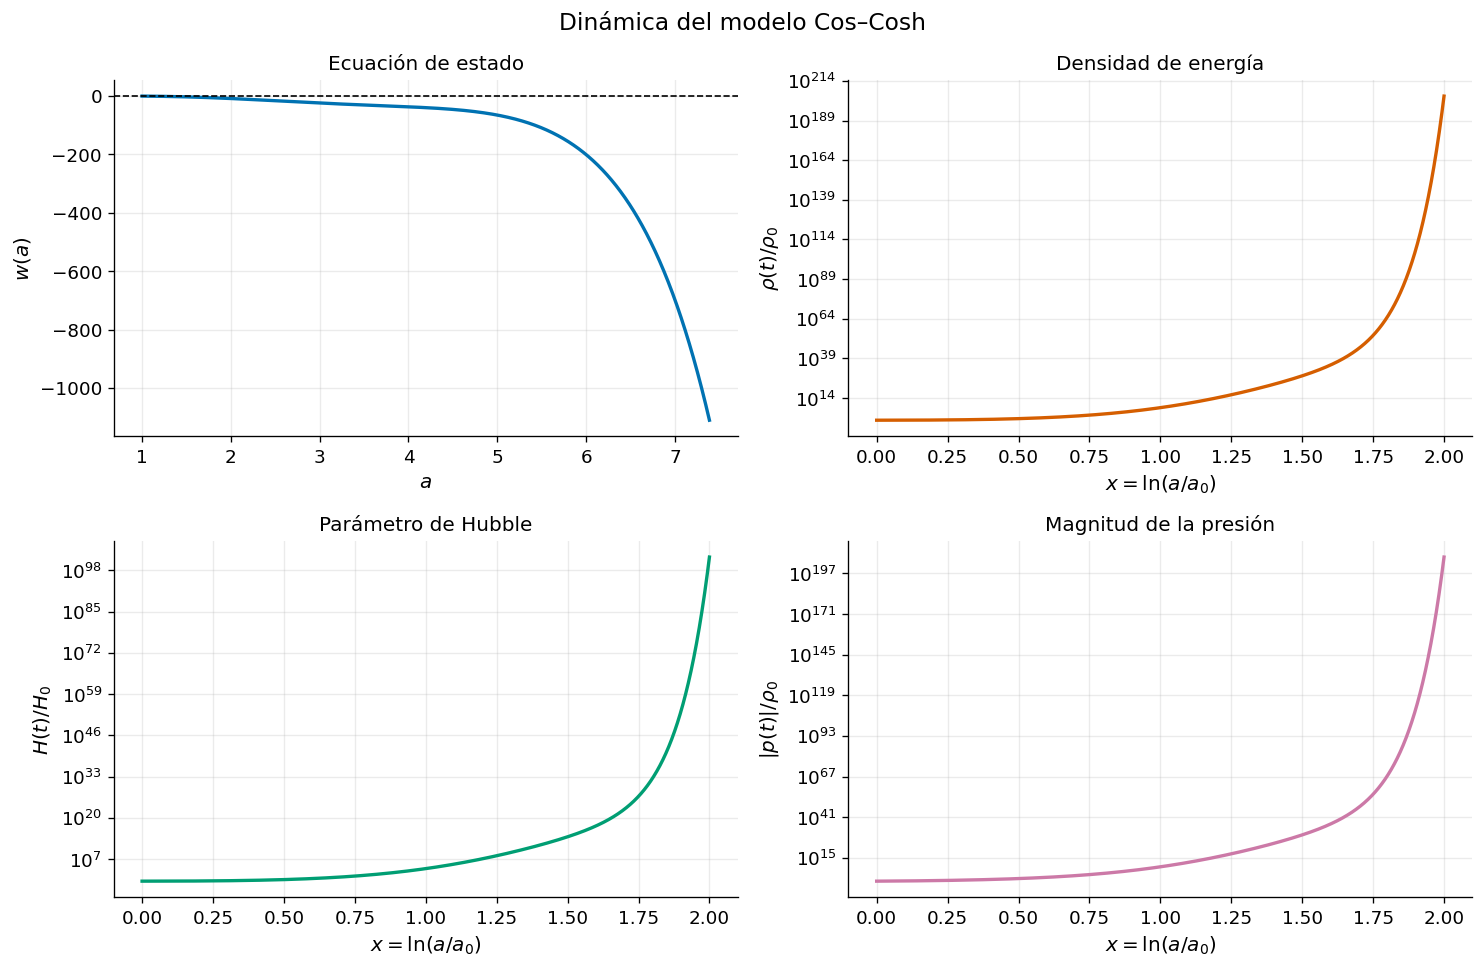

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))
axes = axes.ravel()

axes[0].plot(background["a"], background["w"], color="#0072B2", linewidth=2)
axes[0].axhline(-1.0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel(r"$a$")
axes[0].set_ylabel(r"$w(a)$")
axes[0].set_title("Ecuación de estado")

panels = [
    ("rho", r"$\rho(t)/\rho_0$", "Densidad de energía", "#D55E00"),
    ("H", r"$H(t)/H_0$", "Parámetro de Hubble", "#009E73"),
    ("P", r"$|p(t)|/\rho_0$", "Magnitud de la presión", "#CC79A7"),
]
for ax, (column, ylabel, title, color) in zip(axes[1:], panels):
    values = np.abs(background[column]) if column == "P" else background[column]
    ax.plot(background["x"], values, color=color, linewidth=2)
    ax.set_xlabel(r"$x=\ln(a/a_0)$")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_yscale("log")

for ax in axes:
    ax.grid(True, which="both", alpha=0.25)

fig.suptitle("Dinámica del modelo Cos–Cosh", fontsize=14)
fig.tight_layout()
save_figure(fig, "cos_cosh_evolution")
plt.show()
plt.close(fig)


## 4. Convergencia del tiempo crítico

Para evitar evaluar cantidades divergentes, se compara la estimación
\(t(x_{\max})\) en una secuencia de cortes crecientes. La estabilización
numérica es la evidencia relevante, no el valor infinito de las variables.


In [4]:
x_max_values = [1.0, 1.25, 1.5, 1.75, 2.0]
convergence = pd.DataFrame({
    "x_max": x_max_values,
    "t_estimate": [
        model.estimate_singular_time(x_max=x_max, n_points=4000)
        for x_max in x_max_values
    ],
})
convergence["delta"] = convergence["t_estimate"].diff().abs()
display(convergence)

t_estimate = convergence["t_estimate"].iloc[-1]
assert convergence["delta"].iloc[-1] < 1e-5
print(f"Estimación estabilizada de t_s: {t_estimate:.9f}")


,x_max,t_estimate,delta
0,1.00,0.413804,NaN
1,1.25,0.413807,3.547967e-06
2,1.50,0.413807,1.267391e-08
3,1.75,0.413807,1.521926e-08
4,2.00,0.413807,1.756068e-08


Estimación estabilizada de t_s: 0.413807407


## 5. Conclusión

Para los parámetros utilizados, \(w(a)\) entra en un régimen fuertemente
phantom y la estimación de \(t_s\) se estabiliza al aumentar \(x_{\max}\).
La clasificación cualitativa implementada en `src` es compatible con una
singularidad tipo I (*Big Rip*).
